In [ ]:
!pip -q install fair-esm scipy scikit-learn pandas requests

1、下载数据并获取 GFP 原始蛋白质序列

In [ ]:
import os
import re
import requests
import pandas as pd
import numpy as np

from io import BytesIO
from zipfile import ZipFile
from pathlib import Path



In [ ]:
ASSAY = "GFP_AEQVI_Sarkisyan_2016"

# 获取官方参考文件
ref_url = (
    "https://raw.githubusercontent.com/"
    "OATML-Markslab/ProteinGym/main/"
    "reference_files/DMS_substitutions.csv"
)

response = requests.get(ref_url, timeout=60)
response.raise_for_status()

reference_df = pd.read_csv(BytesIO(response.content))

gfp_ref = reference_df[
    reference_df["DMS_id"] == ASSAY
]

if len(gfp_ref) != 1:
    raise ValueError(
        f"没有唯一找到 {ASSAY}，请检查参考文件中的 DMS_id"
    )

gfp_ref = gfp_ref.iloc[0]

wt_sequence = str(gfp_ref["target_seq"]).strip().upper()

print("Assay:", ASSAY)
print("WT 长度:", len(wt_sequence))
print("WT 序列:", wt_sequence)
print("数据文件:", gfp_ref["DMS_filename"])

assert wt_sequence
assert set(wt_sequence).issubset(
    set("ACDEFGHIKLMNPQRSTVWY")
)

Assay: GFP_AEQVI_Sarkisyan_2016
WT 长度: 238
WT 序列: MSKGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKFICTTGKLPVPWPTLVTTLSYGVQCFSRYPDHMKQHDFFKSAMPEGYVQERTIFFKDDGNYKTRAEVKFEGDTLVNRIELKGIDFKEDGNILGHKLEYNYNSHNVYIMADKQKNGIKVNFKIRHNIEDGSVQLADHYQQNTPIGDGPVLLPDNHYLSTQSALSKDPNEKRDHMVLLEFVTAAGITHGMDELYK
数据文件: GFP_AEQVI_Sarkisyan_2016.csv


2、下载 GFP 突变数据

In [ ]:
zip_url = (
    "https://marks.hms.harvard.edu/"
    "proteingym/ProteinGym_v1.3/"
    "DMS_ProteinGym_substitutions.zip"
)

zip_path = "/content/DMS_ProteinGym_substitutions.zip"

if not os.path.exists(zip_path):
    print("开始下载 ProteinGym 数据包……")

    with requests.get(
        zip_url,
        stream=True,
        timeout=300
    ) as r:
        r.raise_for_status()

        with open(zip_path, "wb") as f:
            for chunk in r.iter_content(
                chunk_size=1024 * 1024
            ):
                if chunk:
                    f.write(chunk)

print("下载完成，文件大小：",
      round(os.path.getsize(zip_path) / 1024**2, 2),
      "MB")

with ZipFile(zip_path) as z:
    all_files = z.namelist()

    matches = [
        name for name in all_files
        if Path(name).name == f"{ASSAY}.csv"
    ]

    if not matches:
        print("压缩包中的候选文件：")
        print([
            name for name in all_files
            if "GFP_AEQVI_Sarkisyan_2016" in name
        ][:20])

        raise FileNotFoundError(
            "没有在压缩包中找到 GFP 对应的 CSV"
        )

    with z.open(matches[0]) as f:
        df = pd.read_csv(f)

print("数据文件:", matches[0])
print("数据形状:", df.shape)
print("列名:", df.columns.tolist())

display(df.head())

开始下载 ProteinGym 数据包……
下载完成，文件大小： 41.03 MB
数据文件: DMS_ProteinGym_substitutions/GFP_AEQVI_Sarkisyan_2016.csv
数据形状: (51714, 4)
列名: ['mutant', 'mutated_sequence', 'DMS_score', 'DMS_score_bin']


,mutant,mutated_sequence,DMS_score,DMS_score_bin
0,K3R:V55A:Q94R:A110T:D117G:M153K:D216A,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,1.301030,0
1,K3Q:V16A:I167T:L195Q,MSQGEELFTGVVPILAELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.137350,1
2,K3Q:Y143C:N164D:S205P:A227T,MSQGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,1.553913,0
3,K3Q:Y143N:V193A,MSQGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.404237,1
4,K3R,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.738586,1


3、检查突变体序列与实验评分

In [ ]:
required = {"mutant", "mutated_sequence", "DMS_score"}

missing = required - set(df.columns)

if missing:
    raise ValueError(f"缺少必要列：{missing}")

df["DMS_score"] = pd.to_numeric(
    df["DMS_score"], errors="coerce"
)

df["mutated_sequence"] = (
    df["mutated_sequence"]
    .fillna("")
    .astype(str)
    .str.strip()
    .str.upper()
)

print("WT 长度:", len(wt_sequence))
print("实验记录数:", len(df))
print("有效实验评分数:", df["DMS_score"].notna().sum())
print("缺失评分数:", df["DMS_score"].isna().sum())
print("缺失突变体序列数:",
      (df["mutated_sequence"] == "").sum())

display(
    df[["mutant", "mutated_sequence", "DMS_score"]]
    .head(10)
)

WT 长度: 238
实验记录数: 51714
有效实验评分数: 51714
缺失评分数: 0
缺失突变体序列数: 0


,mutant,mutated_sequence,DMS_score
0,K3R:V55A:Q94R:A110T:D117G:M153K:D216A,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,1.301030
1,K3Q:V16A:I167T:L195Q,MSQGEELFTGVVPILAELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.137350
2,K3Q:Y143C:N164D:S205P:A227T,MSQGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,1.553913
3,K3Q:Y143N:V193A,MSQGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.404237
4,K3R,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.738586
5,K3R:A87T:D173G,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.851893
6,K3R:A87T:N144S:T225S,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.551648
7,K3R:C48R:D76G:M218K,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,1.480047
8,K3R:D102G:N185D:L195P:H231P:E235K,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.388889
9,K3R:D102G:Y151C:N170D:I229T,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.499501


3、加载 ESM-2，计算零样本突变评分

对于每一个突变位置，先遮蔽 WT 序列中的对应氨基酸，再计算 20 种标准氨基酸的条件概率。单点突变评分定义为：
$$
S_i = \log P(a_i^{mut} \mid x_{\setminus i}) - \log P(a_i^{WT} \mid x_{\setminus i})
$$

对于多点突变，本代码将每个突变的 masked marginal 分数相加，作为加性近似评分。它不是对组合突变真实效应的精确建模

In [ ]:
import torch
import esm
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import mean_squared_error

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("运行设备:", device)

model, alphabet = esm.pretrained.esm2_t6_8M_UR50D()
model = model.eval().to(device)

batch_converter = alphabet.get_batch_converter()

AA = "ACDEFGHIKLMNPQRSTVWY"

_, _, wt_tokens = batch_converter([
    ("WT", wt_sequence)
])

wt_tokens = wt_tokens.to(device)

# 每个位置的 WT marginal 概率差
# 例如 score_table[(4, "E", "A")]
score_table = {}

batch_size = 16

with torch.no_grad():
    for start in range(1, len(wt_sequence) + 1,
                       batch_size):

        positions = list(range(
            start,
            min(start + batch_size, len(wt_sequence) + 1)
        ))

        # 每个样本只遮蔽一个 WT 位置
        batch_tokens = wt_tokens.repeat(
            len(positions), 1
        )

        for row_idx, pos in enumerate(positions):
            batch_tokens[row_idx, pos] = alphabet.mask_idx

        logits = model(batch_tokens)["logits"]
        log_probs = logits.log_softmax(dim=-1)

        for row_idx, pos in enumerate(positions):
            wt_aa = wt_sequence[pos - 1]
            wt_idx = alphabet.get_idx(wt_aa)

            wt_logp = log_probs[
                row_idx, pos, wt_idx
            ].item()

            for alt_aa in AA:
                if alt_aa == wt_aa:
                    continue

                alt_idx = alphabet.get_idx(alt_aa)

                alt_logp = log_probs[
                    row_idx, pos, alt_idx
                ].item()

                score_table[
                    (pos, wt_aa, alt_aa)
                ] = alt_logp - wt_logp

        print(
            f"已完成位置 {positions[0]}–{positions[-1]}"
        )

print("单点突变评分数量:", len(score_table))

运行设备: cuda
Downloading: "https://dl.fbaipublicfiles.com/fair-esm/models/esm2_t6_8M_UR50D.pt" to /root/.cache/torch/hub/checkpoints/esm2_t6_8M_UR50D.pt
Downloading: "https://dl.fbaipublicfiles.com/fair-esm/regression/esm2_t6_8M_UR50D-contact-regression.pt" to /root/.cache/torch/hub/checkpoints/esm2_t6_8M_UR50D-contact-regression.pt
已完成位置 1–16
已完成位置 17–32
已完成位置 33–48
已完成位置 49–64
已完成位置 65–80
已完成位置 81–96
已完成位置 97–112
已完成位置 113–128
已完成位置 129–144
已完成位置 145–160
已完成位置 161–176
已完成位置 177–192
已完成位置 193–208
已完成位置 209–224
已完成位置 225–238
单点突变评分数量: 4522


4、将每个变异体转换为零样本评分

ProteinGym 的 mutant 通常使用 A1P:D2N 这样的格式：WT 第 1 位的 A 替换为 P，第 2 位的 D 替换为 N。

GitHub
+1

In [ ]:
mutation_pattern = re.compile(
    r"([ACDEFGHIKLMNPQRSTVWY])"
    r"(\d+)"
    r"([ACDEFGHIKLMNPQRSTVWY])"
)

def score_variant(mutation):
    if not isinstance(mutation, str):
        raise ValueError("突变注释不是字符串")

    mutation = mutation.strip()

    if mutation.upper() in {"WT", "WILDTYPE"}:
        return 0.0

    variants = mutation.split(":")
    total_score = 0.0
    seen_positions = set()

    for variant in variants:
        match = mutation_pattern.fullmatch(
            variant.strip()
        )

        if not match:
            raise ValueError(
                f"无法解析突变格式: {variant}"
            )

        ref_aa, pos_text, alt_aa = match.groups()
        pos = int(pos_text)

        if not 1 <= pos <= len(wt_sequence):
            raise ValueError(
                f"位置超出 WT 序列范围: {variant}"
            )

        if wt_sequence[pos - 1] != ref_aa:
            raise ValueError(
                f"参考氨基酸不匹配: {variant}; "
                f"WT 对应位置为 {wt_sequence[pos - 1]}"
            )

        if pos in seen_positions:
            raise ValueError(
                f"同一位置重复出现: {variant}"
            )

        seen_positions.add(pos)

        if ref_aa == alt_aa:
            raise ValueError(
                f"不是实际氨基酸替换: {variant}"
            )

        total_score += score_table[
            (pos, ref_aa, alt_aa)
        ]

    return total_score


scores = []
statuses = []

for mutation in df["mutant"]:
    try:
        scores.append(score_variant(mutation))
        statuses.append("OK")
    except (ValueError, KeyError) as e:
        scores.append(np.nan)
        statuses.append(str(e))

df["ESM2_zero_shot_score"] = scores
df["score_status"] = statuses

print("评分成功:", (df["score_status"] == "OK").sum())
print("评分失败:", (df["score_status"] != "OK").sum())

display(
    df[[
        "mutant",
        "DMS_score",
        "ESM2_zero_shot_score",
        "score_status"
    ]].head(20)
)

评分成功: 51714
评分失败: 0


,mutant,DMS_score,ESM2_zero_shot_score,score_status
0,K3R:V55A:Q94R:A110T:D117G:M153K:D216A,1.301030,0.344007,OK
1,K3Q:V16A:I167T:L195Q,3.137350,-3.234258,OK
2,K3Q:Y143C:N164D:S205P:A227T,1.553913,-2.627125,OK
3,K3Q:Y143N:V193A,3.404237,-2.095721,OK
4,K3R,3.738586,-1.269841,OK
5,K3R:A87T:D173G,3.851893,-1.316694,OK
6,K3R:A87T:N144S:T225S,3.551648,-1.181409,OK
7,K3R:C48R:D76G:M218K,1.480047,0.968848,OK
8,K3R:D102G:N185D:L195P:H231P:E235K,3.388889,-1.311800,OK
9,K3R:D102G:Y151C:N170D:I229T,3.499501,-2.775595,OK


5、检查序列并评价零样本模型

In [ ]:
# 检查数据中的突变序列是否是标准氨基酸序列
valid_alphabet = set(AA)

df["sequence_valid"] = df["mutated_sequence"].apply(
    lambda s: (
        len(s) == len(wt_sequence)
        and set(s).issubset(valid_alphabet)
    )
)

print("等长且合法的突变序列比例:",
      df["sequence_valid"].mean())

# 只评估有实验分数、评分成功的记录
eval_df = df[
    df["DMS_score"].notna()
    & df["ESM2_zero_shot_score"].notna()
].copy()

if len(eval_df) < 3:
    raise ValueError("有效评估记录不足")

spearman = spearmanr(
    eval_df["DMS_score"],
    eval_df["ESM2_zero_shot_score"]
)

pearson = pearsonr(
    eval_df["DMS_score"],
    eval_df["ESM2_zero_shot_score"]
)

rmse = np.sqrt(mean_squared_error(
    eval_df["DMS_score"],
    eval_df["ESM2_zero_shot_score"]
))

print("有效评估样本数:", len(eval_df))
print(f"Spearman rho: {spearman.statistic:.4f}")
print(f"Spearman p-value: {spearman.pvalue:.3e}")
print(f"Pearson r: {pearson.statistic:.4f}")
print(f"Pearson p-value: {pearson.pvalue:.3e}")
print(f"RMSE: {rmse:.4f}")

等长且合法的突变序列比例: 1.0
有效评估样本数: 51714
Spearman rho: 0.0782
Spearman p-value: 5.215e-71
Pearson r: 0.0941
Pearson p-value: 6.130e-102
RMSE: 3.5155


In [ ]:
output_path = "/content/GFP_ESM2_zero_shot_results.csv"

df.to_csv(output_path, index=False)

print("结果已保存:", output_path)

from google.colab import files
files.download(output_path)

结果已保存: /content/GFP_ESM2_zero_shot_results.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

6、lora微调esm2

In [ ]:

import numpy as np
import pandas as pd
import torch
import random

from sklearn.model_selection import GroupShuffleSplit
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import mean_squared_error

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

required = {"mutated_sequence", "DMS_score"}
assert required.issubset(df.columns), (
    f"缺少列：{required - set(df.columns)}"
)

data = df[["mutated_sequence", "DMS_score"]].copy()
data["mutated_sequence"] = (
    data["mutated_sequence"].astype(str).str.strip().str.upper()
)
data["DMS_score"] = pd.to_numeric(
    data["DMS_score"], errors="coerce"
)

AA = set("ACDEFGHIKLMNPQRSTVWY")

data = data.dropna(subset=["DMS_score"])
data = data[
    data["mutated_sequence"].apply(
        lambda s: len(s) > 0 and set(s).issubset(AA)
    )
].reset_index(drop=True)

# 同一条序列可能有重复记录，避免同一序列跨集合泄漏
data["group"] = data["mutated_sequence"]

print("有效记录数:", len(data))
print("唯一序列数:", data["group"].nunique())
print(data["DMS_score"].describe())
display(data.head())


有效记录数: 51714
唯一序列数: 51714
count    51714.000000
mean         2.657945
std          1.058574
min          1.283419
25%          1.428543
50%          3.287286
75%          3.615593
max          4.123109
Name: DMS_score, dtype: float64


,mutated_sequence,DMS_score,group
0,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,1.301030,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...
1,MSQGEELFTGVVPILAELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.137350,MSQGEELFTGVVPILAELDGDVNGHKFSVSGEGEGDATYGKLTLKF...
2,MSQGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,1.553913,MSQGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...
3,MSQGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.404237,MSQGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...
4,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.738586,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...


7、划分训练集、验证集和测试集

这是一种防止完全相同序列泄漏的划分，但不等于严格的突变位置或蛋白质家族外推测试。由于所有样本来自 GFP 同一个蛋白质，结论也应限定于该实验体系。

In [ ]:

# 第一步：留出 20% 的唯一序列作为测试集
split1 = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=SEED
)

trainval_idx, test_idx = next(
    split1.split(data, groups=data["group"])
)

trainval = data.iloc[trainval_idx].reset_index(drop=True)
test = data.iloc[test_idx].reset_index(drop=True)

# 第二步：从剩余数据中留出 15% 作为验证集
split2 = GroupShuffleSplit(
    n_splits=1, test_size=0.15, random_state=SEED + 1
)

train_idx, val_idx = next(
    split2.split(trainval, groups=trainval["group"])
)

train = trainval.iloc[train_idx].reset_index(drop=True)
val = trainval.iloc[val_idx].reset_index(drop=True)

print("Train:", len(train))
print("Validation:", len(val))
print("Test:", len(test))

assert set(train["group"]).isdisjoint(val["group"])
assert set(train["group"]).isdisjoint(test["group"])
assert set(val["group"]).isdisjoint(test["group"])


Train: 35165
Validation: 6206
Test: 10343


8加载 ESM-2 并手写 LoRA

这里将 LoRA 添加到每层注意力模块的 q_proj 和 v_proj，冻结原始 ESM-2 参数，只训练 LoRA 参数和回归头。

In [ ]:

!pip -q install fair-esm


In [ ]:

import esm
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

base_model, alphabet = esm.pretrained.esm2_t6_8M_UR50D()
base_model.eval()

# 冻结全部预训练参数
for p in base_model.parameters():
    p.requires_grad = False


class LoRALinear(nn.Module):
    def __init__(self, base_linear, rank=4, alpha=8, dropout=0.05):
        super().__init__()

        self.base = base_linear
        self.rank = rank
        self.scale = alpha / rank

        for p in self.base.parameters():
            p.requires_grad = False

        in_features = base_linear.in_features
        out_features = base_linear.out_features

        self.lora_A = nn.Parameter(
            torch.empty(rank, in_features)
        )
        self.lora_B = nn.Parameter(
            torch.zeros(out_features, rank)
        )

        nn.init.kaiming_uniform_(self.lora_A, a=5**0.5)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        base_output = self.base(x)

        # (x A^T) B^T
        lora_output = F.linear(
            F.linear(self.dropout(x), self.lora_A),
            self.lora_B
        )

        return base_output + self.scale * lora_output


# 给每层注意力中的 query 和 value 投影添加 LoRA
for layer in base_model.layers:
    layer.self_attn.q_proj = LoRALinear(
        layer.self_attn.q_proj, rank=4, alpha=8
    )
    layer.self_attn.v_proj = LoRALinear(
        layer.self_attn.v_proj, rank=4, alpha=8
    )


class ESM2LoRARegressor(nn.Module):
    def __init__(self, esm_model, embed_dim=320):
        super().__init__()
        self.esm = esm_model

        self.regressor = nn.Sequential(
            nn.Linear(embed_dim, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, 1)
        )

    def forward(self, tokens):
        output = self.esm(
            tokens,
            repr_layers=[6]
        )

        # [batch, sequence_length, embedding_dim]
        h = output["representations"][6]

        # 排除 BOS、EOS 和 padding，只平均真实氨基酸位置
        mask = (
            tokens.ne(alphabet.padding_idx)
            & tokens.ne(alphabet.cls_idx)
            & tokens.ne(alphabet.eos_idx)
        )

        mask = mask.unsqueeze(-1).to(h.dtype)
        pooled = (h * mask).sum(dim=1)
        pooled = pooled / mask.sum(dim=1).clamp(min=1)

        return self.regressor(pooled).squeeze(-1)


model = ESM2LoRARegressor(base_model).to(device)

trainable = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)
total = sum(p.numel() for p in model.parameters())

print(f"可训练参数: {trainable:,}")
print(f"总参数: {total:,}")
print(f"可训练参数比例: {100 * trainable / total:.2f}%")


可训练参数: 71,937
总参数: 7,584,411
可训练参数比例: 0.95%


防止完全相同序列泄漏的划分，但不等于严格的突变位置或蛋白质家族外推测试。由于所有样本来自 GFP 同一个蛋白质，结论也应限定于该实验体系。

In [ ]:

batch_converter = alphabet.get_batch_converter()

class GFPDataset(Dataset):
    def __init__(self, frame):
        self.sequences = frame["mutated_sequence"].tolist()
        self.labels = frame["DMS_score"].astype(float).to_numpy()

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, idx):
        return self.sequences[idx], float(self.labels[idx])


y_mean = float(train["DMS_score"].mean())
y_std = float(train["DMS_score"].std())

if not np.isfinite(y_std) or y_std < 1e-8:
    y_std = 1.0


def collate_fn(batch):
    sequences, labels = zip(*batch)

    _, _, tokens = batch_converter([
        (str(i), seq)
        for i, seq in enumerate(sequences)
    ])

    labels = torch.tensor(
        [(y - y_mean) / y_std for y in labels],
        dtype=torch.float32
    )

    return tokens, labels


BATCH_SIZE = 16

train_loader = DataLoader(
    GFPDataset(train),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    GFPDataset(val),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    GFPDataset(test),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_fn
)

print("训练批次数:", len(train_loader))
print("验证批次数:", len(val_loader))


训练批次数: 2198
验证批次数: 388


9、训练 LoRA 微调模型

In [ ]:


from copy import deepcopy
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import mean_squared_error
from IPython.display import clear_output, display

EPOCHS = 5
LR = 1e-3
PATIENCE = 2

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=LR,
    weight_decay=0.01
)

best_val_rmse = float("inf")
best_state = None
bad_epochs = 0
history = []


def evaluate(loader):
    model.eval()
    all_true, all_pred = [], []

    with torch.no_grad():
        for tokens, labels in loader:
            tokens = tokens.to(device)
            labels = labels.to(device)

            pred = model(tokens)

            # 还原到原始 DMS_score 尺度
            pred = pred * y_std + y_mean
            labels = labels * y_std + y_mean

            all_true.extend(labels.cpu().numpy())
            all_pred.extend(pred.cpu().numpy())

    y_true = np.asarray(all_true)
    y_pred = np.asarray(all_pred)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    rho = spearmanr(y_true, y_pred).statistic
    r = pearsonr(y_true, y_pred).statistic

    return {
        "rmse": float(rmse),
        "spearman": float(rho),
        "pearson": float(r),
        "y_true": y_true,
        "y_pred": y_pred
    }


print("开始训练 ESM-2 + LoRA")
print("设备:", device)
print("Epoch 数:", EPOCHS)
print("训练样本:", len(train_loader.dataset))
print("验证样本:", len(val_loader.dataset))
print("-" * 70)

for epoch in range(EPOCHS):
    model.train()
    losses = []

    # 每个 Epoch 显示 Batch 进度
    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch+1}/{EPOCHS}",
        unit="batch",
        leave=True
    )

    for step, (tokens, labels) in enumerate(progress):
        tokens = tokens.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        predictions = model(tokens)
        loss = F.mse_loss(predictions, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            [p for p in model.parameters() if p.requires_grad],
            max_norm=1.0
        )

        optimizer.step()

        losses.append(loss.item())

        # 实时显示当前 Batch 的 Loss
        progress.set_postfix(
            batch_loss=f"{loss.item():.4f}",
            avg_loss=f"{np.mean(losses):.4f}"
        )

    train_loss = float(np.mean(losses))

    # 每个 Epoch 结束后评估验证集
    val_metrics = evaluate(val_loader)

    record = {
        "epoch": epoch + 1,
        "train_mse": train_loss,
        "val_rmse": val_metrics["rmse"],
        "val_spearman": val_metrics["spearman"],
        "val_pearson": val_metrics["pearson"],
        "lr": optimizer.param_groups[0]["lr"]
    }
    history.append(record)

    improved = val_metrics["rmse"] < best_val_rmse

    if improved:
        best_val_rmse = val_metrics["rmse"]

        best_state = {
            name: param.detach().cpu().clone()
            for name, param in model.named_parameters()
            if param.requires_grad
        }

        bad_epochs = 0
        status = "保存最佳模型"
    else:
        bad_epochs += 1
        status = f"验证集未改善 ({bad_epochs}/{PATIENCE})"

    print(
        f"\nEpoch {epoch+1}/{EPOCHS} 完成 | "
        f"Train MSE: {train_loss:.4f} | "
        f"Val RMSE: {val_metrics['rmse']:.4f} | "
        f"Val Spearman: {val_metrics['spearman']:.4f} | "
        f"Val Pearson: {val_metrics['pearson']:.4f}"
    )
    print(status)
    print("-" * 70)

    if bad_epochs >= PATIENCE:
        print("触发 Early Stopping，结束训练。")
        break


# 恢复验证集表现最好的参数
assert best_state is not None

with torch.no_grad():
    for name, param in model.named_parameters():
        if param.requires_grad:
            param.copy_(best_state[name].to(param.device))

history_df = pd.DataFrame(history)

print("\n训练结束！最佳验证集 RMSE:", round(best_val_rmse, 4))
display(history_df.round(4))


开始训练 ESM-2 + LoRA
设备: cuda
Epoch 数: 5
训练样本: 35165
验证样本: 6206
----------------------------------------------------------------------


Epoch 1/5:   0%|          | 0/2198 [00:00<?, ?batch/s]


Epoch 1/5 完成 | Train MSE: 0.5127 | Val RMSE: 0.4995 | Val Spearman: 0.8102 | Val Pearson: 0.8998
保存最佳模型
----------------------------------------------------------------------


Epoch 2/5:   0%|          | 0/2198 [00:00<?, ?batch/s]


Epoch 2/5 完成 | Train MSE: 0.2461 | Val RMSE: 0.4246 | Val Spearman: 0.8376 | Val Pearson: 0.9217
保存最佳模型
----------------------------------------------------------------------


...

Epoch 4/5:   0%|          | 0/2198 [00:00<?, ?batch/s]


Epoch 4/5 完成 | Train MSE: 0.1534 | Val RMSE: 0.3435 | Val Spearman: 0.8512 | Val Pearson: 0.9484
保存最佳模型
----------------------------------------------------------------------


Epoch 5/5:   0%|          | 0/2198 [00:00<?, ?batch/s]


Epoch 5/5 完成 | Train MSE: 0.1390 | Val RMSE: 0.3535 | Val Spearman: 0.8543 | Val Pearson: 0.9453
验证集未改善 (1/2)
----------------------------------------------------------------------

训练结束！最佳验证集 RMSE: 0.3435


,epoch,train_mse,val_rmse,val_spearman,val_pearson,lr
0,1,0.5127,0.4995,0.8102,0.8998,0.001
1,2,0.2461,0.4246,0.8376,0.9217,0.001
2,3,0.1852,0.4432,0.8452,0.9294,0.001
3,4,0.1534,0.3435,0.8512,0.9484,0.001
4,5,0.1390,0.3535,0.8543,0.9453,0.001


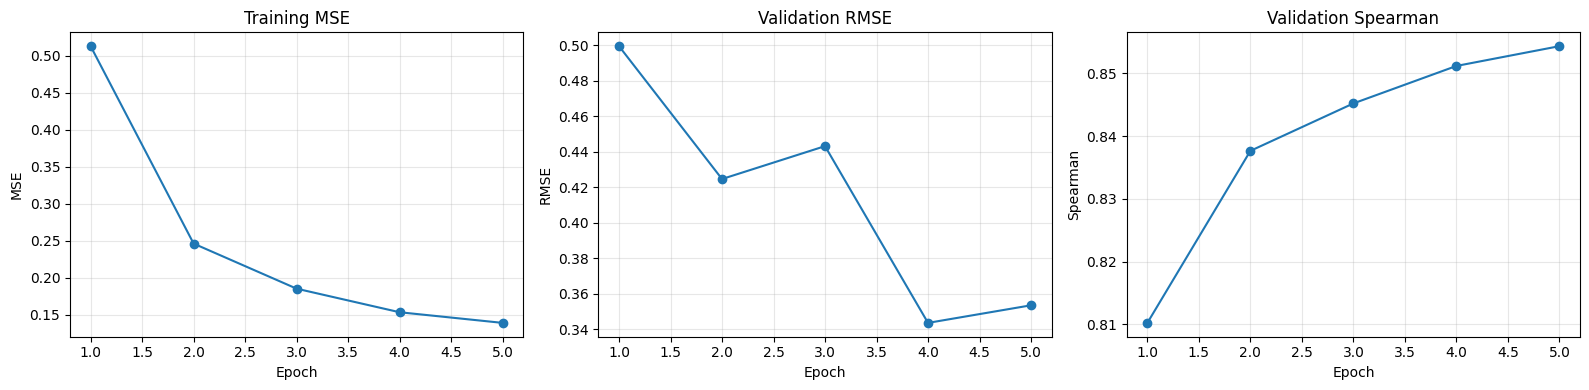

In [ ]:

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

# 1. 训练 MSE
axes[0].plot(
    history_df["epoch"],
    history_df["train_mse"],
    marker="o"
)
axes[0].set_title("Training MSE")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE")
axes[0].grid(True, alpha=0.3)

# 2. 验证 RMSE
axes[1].plot(
    history_df["epoch"],
    history_df["val_rmse"],
    marker="o"
)
axes[1].set_title("Validation RMSE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("RMSE")
axes[1].grid(True, alpha=0.3)

# 3. 验证 Spearman
axes[2].plot(
    history_df["epoch"],
    history_df["val_spearman"],
    marker="o"
)
axes[2].set_title("Validation Spearman")
axes[2].set_xlabel("Epoch")
axes[2].set_ylabel("Spearman")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


10、在测试集上评估

In [ ]:

test_metrics = evaluate(test_loader)

print("===== GFP LoRA 最终测试结果 =====")
print("Test RMSE:", round(test_metrics["rmse"], 4))
print("Test Spearman:", round(test_metrics["spearman"], 4))
print("Test Pearson:", round(test_metrics["pearson"], 4))

predictions_df = test[
    ["mutated_sequence", "DMS_score"]
].copy()

predictions_df["predicted_DMS_score"] = (
    test_metrics["y_pred"]
)

display(predictions_df.head(20))


===== GFP LoRA 最终测试结果 =====
Test RMSE: 0.3237
Test Spearman: 0.8538
Test Pearson: 0.955


,mutated_sequence,DMS_score,predicted_DMS_score
0,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.716293,3.571338
1,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.617822,3.401614
2,MSNGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.139985,3.466592
3,MSNGEELFTGVVPVLVELDGDVNGHKFSVSGEGEGDAAYGKLTLKF...,1.301030,1.564510
4,MSNGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.553744,3.543013
5,MSQGEELFTGVVPILVELDGDVNGHKFSVSGVGEGDATYGKLTLKF...,3.656721,3.375302
6,MSQGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.654081,3.516918
7,MSQGEELFTGVVPIQVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.560393,3.534886
8,MSQGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,1.301030,1.451397
9,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGVCDATYGKLTLKF...,1.428584,3.295738


In [ ]:

import os
import shutil
import torch
import pandas as pd
from google.colab import files

# 1. 创建输出目录，不依赖 Google Drive 中已有的文件夹
project_dir = "/content/GFP_ESM2_LoRA"
os.makedirs(project_dir, exist_ok=True)

# 2. 保存 LoRA 参数和回归头参数
trainable_state = {
    name: param.detach().cpu().clone()
    for name, param in model.named_parameters()
    if param.requires_grad
}

torch.save(
    {
        "trainable_state": trainable_state,
        "y_mean": y_mean,
        "y_std": y_std,
        "model_name": "esm2_t6_8M_UR50D",
        "lora_rank": 4,
        "lora_alpha": 8,
        "best_val_rmse": best_val_rmse,
    },
    os.path.join(project_dir, "lora_checkpoint.pt")
)

# 3. 保存训练历史
if "history_df" in globals():
    history_df.to_csv(
        os.path.join(project_dir, "training_history.csv"),
        index=False
    )

# 4. 保存测试集预测结果
if "predictions_df" in globals():
    predictions_df.to_csv(
        os.path.join(project_dir, "test_predictions.csv"),
        index=False
    )

# 5. 保存最终测试指标
if "test_metrics" in globals():
    metrics = {
        "test_rmse": test_metrics["rmse"],
        "test_spearman": test_metrics["spearman"],
        "test_pearson": test_metrics["pearson"],
    }
    pd.DataFrame([metrics]).to_csv(
        os.path.join(project_dir, "test_metrics.csv"),
        index=False
    )

# 6. 保存零样本评分数据（如果已经计算）
if "df" in globals() and "ESM2_zero_shot_score" in df.columns:
    df.to_csv(
        os.path.join(project_dir, "zero_shot_results.csv"),
        index=False
    )

# 7. 打包
zip_path = shutil.make_archive(
    "/content/GFP_ESM2_LoRA",
    "zip",
    root_dir=project_dir
)

print("项目目录：", project_dir)
print("输出文件：", os.listdir(project_dir))
print(f"压缩包大小：{os.path.getsize(zip_path) / 1024**2:.2f} MB")

# 8. 下载压缩包
files.download(zip_path)


项目目录： /content/GFP_ESM2_LoRA
输出文件： ['lora_checkpoint.pt', 'test_metrics.csv', 'training_history.csv', 'zero_shot_results.csv', 'test_predictions.csv']
压缩包大小：2.45 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

11、对比零样本和 LoRA 微调

In [ ]:

if "ESM2_zero_shot_score" in df.columns:
    comparison = test[
        ["mutated_sequence", "DMS_score"]
    ].merge(
        df[["mutated_sequence", "ESM2_zero_shot_score"]],
        on="mutated_sequence",
        how="left"
    ).dropna()

    print("共同评估样本数:", len(comparison))

    print(
        "零样本 Spearman:",
        spearmanr(
            comparison["DMS_score"],
            comparison["ESM2_zero_shot_score"]
        ).statistic
    )

    print(
        "LoRA 测试集 Spearman:",
        test_metrics["spearman"]
    )
else:
    print(
        "当前 df 没有零样本评分列。"
        "请先生成零样本评分，再进行对比。"
    )


共同评估样本数: 10343
零样本 Spearman: 0.09498956463652926
LoRA 测试集 Spearman: 0.853822396888494


12、比较图

In [ ]:
import numpy as np
import pandas as pd

# test：之前划分的测试集
# test_metrics：LoRA 测试结果（y_pred 与 test 行顺序一一对应）
# df：原始数据，包含 ESM2_zero_shot_score

# 1) 零样本评分表：每条序列只保留一条
zero_shot = (
    df[["mutated_sequence", "DMS_score", "ESM2_zero_shot_score"]]
    .dropna(subset=["DMS_score", "ESM2_zero_shot_score"])
    .drop_duplicates(subset=["mutated_sequence"])
    .reset_index(drop=True)
)

# 2) LoRA 预测表：先按 test 行顺序赋值，再去重
lora_predictions = test[["mutated_sequence", "DMS_score"]].copy().reset_index(drop=True)
lora_predictions["LoRA_prediction"] = test_metrics["y_pred"]
lora_predictions = (
    lora_predictions
    .drop_duplicates(subset=["mutated_sequence"])
    .reset_index(drop=True)
)

# 3) 以 test 为左表构建 comparison
comparison = (
    test[["mutated_sequence", "DMS_score"]]
    .drop_duplicates(subset=["mutated_sequence"])
    .reset_index(drop=True)
    .merge(
        zero_shot[["mutated_sequence", "ESM2_zero_shot_score"]],
        on="mutated_sequence",
        how="inner",
    )
    .merge(
        lora_predictions[["mutated_sequence", "LoRA_prediction"]],
        on="mutated_sequence",
        how="inner",
    )
    .rename(columns={"DMS_score": "experimental_score"})
)

comparison = comparison.dropna(
    subset=["experimental_score", "ESM2_zero_shot_score", "LoRA_prediction"]
).reset_index(drop=True)

print("共同测试样本数:", len(comparison))
display(comparison.head())

共同测试样本数: 10343


,mutated_sequence,experimental_score,ESM2_zero_shot_score,LoRA_prediction
0,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.716293,-1.657861,3.571338
1,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.617822,0.008822,3.401614
2,MSNGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.139985,-3.300246,3.466592
3,MSNGEELFTGVVPVLVELDGDVNGHKFSVSGEGEGDAAYGKLTLKF...,1.301030,-2.116744,1.564510
4,MSNGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.553744,-0.510668,3.543013


计算两种模型的评价指标

由于零样本分数是对数概率差，而 LoRA 输出的是实验评分预测值，Spearman 相关系数最适合用来比较排序能力。RMSE 只在预测值与实验标签具有可比尺度时才有直接意义。

In [ ]:
def calculate_metrics(y_true, y_pred):
    return {
        "Spearman": spearmanr(y_true, y_pred).statistic,
        "Pearson": pearsonr(y_true, y_pred).statistic,
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred))
    }

y_true = comparison["experimental_score"].to_numpy()

zero_metrics = calculate_metrics(
    y_true,
    comparison["ESM2_zero_shot_score"].to_numpy()
)

lora_metrics = calculate_metrics(
    y_true,
    comparison["LoRA_prediction"].to_numpy()
)

metrics_df = pd.DataFrame(
    [zero_metrics, lora_metrics],
    index=["ESM-2 Zero-shot", "ESM-2 LoRA"]
)

display(metrics_df.round(4))

,Spearman,Pearson,RMSE
ESM-2 Zero-shot,0.0950,0.1155,3.5206
ESM-2 LoRA,0.8538,0.9550,0.3237


实验评分与预测评分散点图

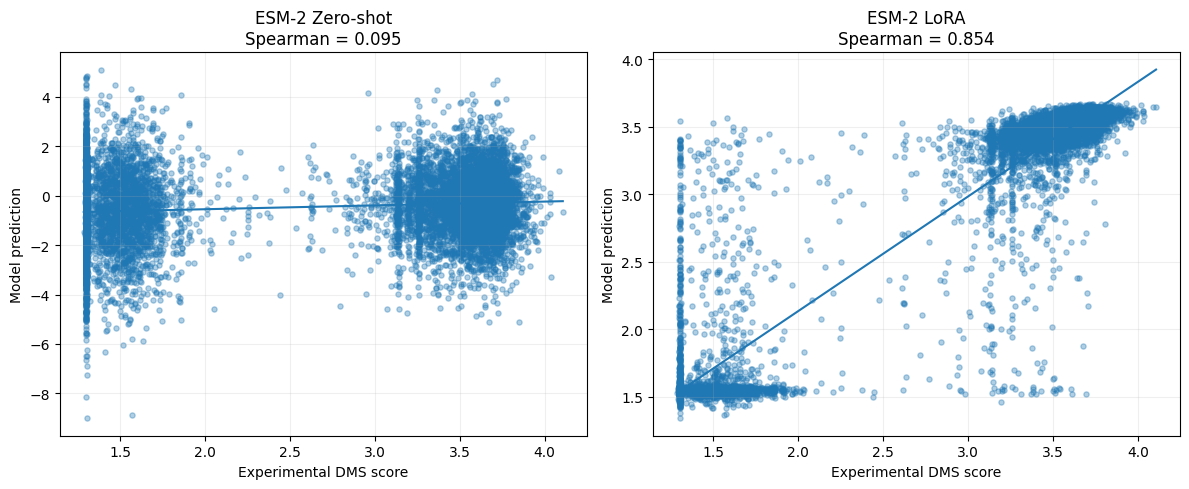

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

methods = [
    ("ESM2_zero_shot_score", "ESM-2 Zero-shot", zero_metrics),
    ("LoRA_prediction", "ESM-2 LoRA", lora_metrics)
]

for ax, (column, title, metrics) in zip(axes, methods):
    x = comparison["experimental_score"].to_numpy()
    y = comparison[column].to_numpy()

    ax.scatter(x, y, alpha=0.35, s=14)

    # 用于观察趋势的线性拟合线
    if len(x) > 1:
        slope, intercept = np.polyfit(x, y, 1)
        xline = np.linspace(x.min(), x.max(), 100)
        ax.plot(xline, slope * xline + intercept)

    ax.set_title(
        f"{title}\nSpearman = {metrics['Spearman']:.3f}"
    )
    ax.set_xlabel("Experimental DMS score")
    ax.set_ylabel("Model prediction")
    ax.grid(True, alpha=0.2)

plt.tight_layout()
plt.show()


Spearman 相关系数对比

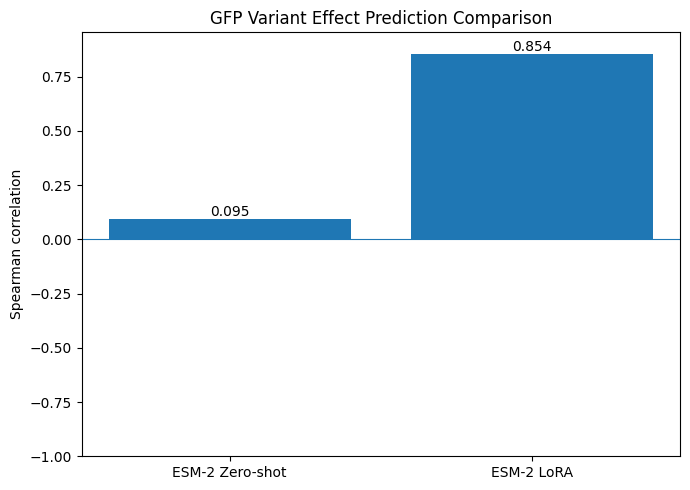

In [ ]:
names = ["ESM-2 Zero-shot", "ESM-2 LoRA"]
spearman_values = [
    zero_metrics["Spearman"],
    lora_metrics["Spearman"]
]

plt.figure(figsize=(7, 5))
bars = plt.bar(names, spearman_values)

plt.axhline(0, linewidth=0.8)
plt.ylabel("Spearman correlation")
plt.title("GFP Variant Effect Prediction Comparison")
plt.ylim(
    min(-1, min(spearman_values) - 0.1),
    min(1, max(spearman_values) + 0.1)
)

for bar, value in zip(bars, spearman_values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.3f}",
        ha="center",
        va="bottom" if value >= 0 else "top"
    )

plt.tight_layout()
plt.show()

逐样本预测对比

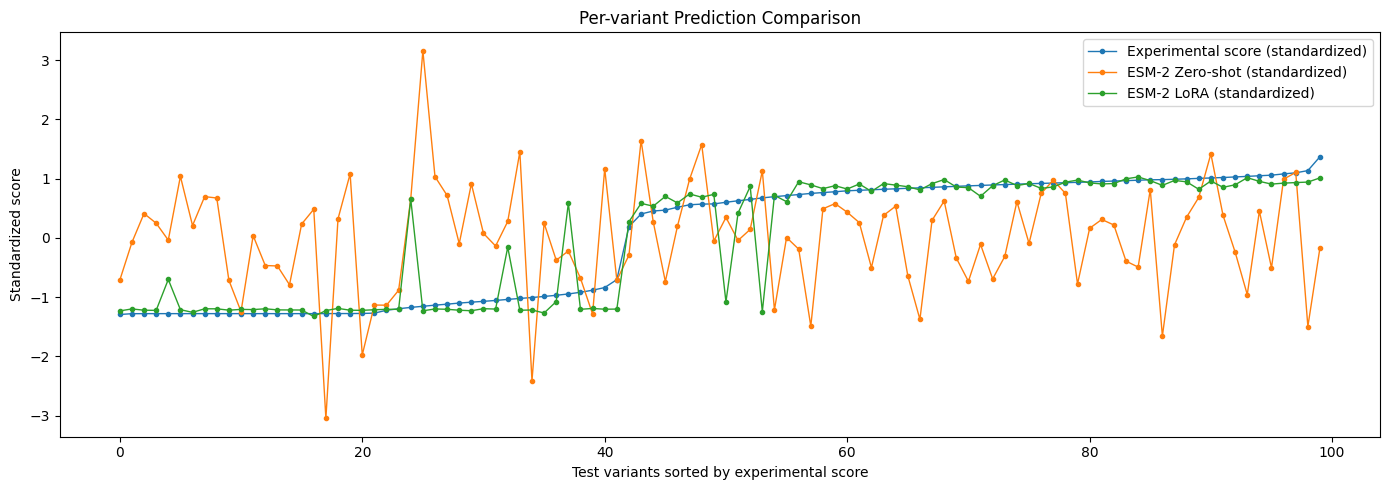

In [ ]:
plot_df = comparison.copy()

for col in [
    "experimental_score",
    "ESM2_zero_shot_score",
    "LoRA_prediction"
]:
    sd = plot_df[col].std()
    if sd > 0:
        plot_df[col + "_z"] = (
            plot_df[col] - plot_df[col].mean()
        ) / sd
    else:
        plot_df[col + "_z"] = 0.0

# 取最多 100 个样本，按实验评分排序
plot_df = plot_df.sort_values(
    "experimental_score"
).reset_index(drop=True)

if len(plot_df) > 100:
    idx = np.linspace(
        0, len(plot_df) - 1, 100
    ).astype(int)
    plot_df = plot_df.iloc[idx]

plt.figure(figsize=(14, 5))

plt.plot(
    plot_df["experimental_score_z"].to_numpy(),
    label="Experimental score (standardized)",
    marker=".",
    linewidth=1
)

plt.plot(
    plot_df["ESM2_zero_shot_score_z"].to_numpy(),
    label="ESM-2 Zero-shot (standardized)",
    marker=".",
    linewidth=1
)

plt.plot(
    plot_df["LoRA_prediction_z"].to_numpy(),
    label="ESM-2 LoRA (standardized)",
    marker=".",
    linewidth=1
)

plt.xlabel("Test variants sorted by experimental score")
plt.ylabel("Standardized score")
plt.title("Per-variant Prediction Comparison")
plt.legend()
plt.tight_layout()
plt.show()

35M model

In [ ]:

SEED35 = 42
EPOCHS35 = 5
LR35 = 1e-3
PATIENCE35 = 2

LORA_RANK35 = 4
LORA_ALPHA35 = 8
LORA_DROPOUT35 = 0.05

torch.manual_seed(SEED35)
np.random.seed(SEED35)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED35)

device35 = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("设备:", device35)
print("加载 ESM-2 35M...")


设备: cuda
加载 ESM-2 35M...


加载 35M 预训练模型

In [ ]:

base_model35, alphabet35 = (
    esm.pretrained.esm2_t12_35M_UR50D()
)

base_model35 = base_model35.to(device35)

# 冻结预训练模型原有参数
for p in base_model35.parameters():
    p.requires_grad = False

Downloading: "https://dl.fbaipublicfiles.com/fair-esm/models/esm2_t12_35M_UR50D.pt" to /root/.cache/torch/hub/checkpoints/esm2_t12_35M_UR50D.pt
Downloading: "https://dl.fbaipublicfiles.com/fair-esm/regression/esm2_t12_35M_UR50D-contact-regression.pt" to /root/.cache/torch/hub/checkpoints/esm2_t12_35M_UR50D-contact-regression.pt


手写 LoRA

In [ ]:







class LoRALinear35(nn.Module):
    def __init__(
        self,
        base_linear,
        rank=4,
        alpha=8,
        dropout=0.05
    ):
        super().__init__()

        self.base = base_linear
        self.scale = alpha / rank

        for p in self.base.parameters():
            p.requires_grad = False

        in_features = base_linear.in_features
        out_features = base_linear.out_features

        self.lora_A = nn.Parameter(
            torch.empty(rank, in_features)
        )

        self.lora_B = nn.Parameter(
            torch.zeros(out_features, rank)
        )

        nn.init.kaiming_uniform_(
            self.lora_A,
            a=5**0.5
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        base_output = self.base(x)

        lora_output = F.linear(
            F.linear(
                self.dropout(x),
                self.lora_A
            ),
            self.lora_B
        )

        return base_output + self.scale * lora_output


# 在 12 层注意力模块的 q_proj 和 v_proj 中添加 LoRA
for layer in base_model35.layers:
    layer.self_attn.q_proj = LoRALinear35(
        layer.self_attn.q_proj,
        rank=LORA_RANK35,
        alpha=LORA_ALPHA35,
        dropout=LORA_DROPOUT35
    )

    layer.self_attn.v_proj = LoRALinear35(
        layer.self_attn.v_proj,
        rank=LORA_RANK35,
        alpha=LORA_ALPHA35,
        dropout=LORA_DROPOUT35
    )




 35M 回归模型

ESM-2 35M: embedding dimension = 480

 最后一层表示: layer 12

In [ ]:

class ESM2LoRARegressor35(nn.Module):
    def __init__(self, esm_model, alphabet):
        super().__init__()

        self.esm = esm_model
        self.alphabet = alphabet

        self.regressor = nn.Sequential(
            nn.Linear(480, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, 1)
        )

    def forward(self, tokens):
        output = self.esm(
            tokens,
            repr_layers=[12]
        )

        h = output["representations"][12]

        # 排除 BOS、EOS 和 padding
        mask = (
            tokens.ne(self.alphabet.padding_idx)
            & tokens.ne(self.alphabet.cls_idx)
            & tokens.ne(self.alphabet.eos_idx)
        )

        mask = mask.unsqueeze(-1).to(h.dtype)

        pooled = (h * mask).sum(dim=1)
        pooled = pooled / mask.sum(dim=1).clamp(min=1)

        return self.regressor(pooled).squeeze(-1)


model35 = ESM2LoRARegressor35(
    base_model35,
    alphabet35
).to(device35)

trainable35 = sum(
    p.numel()
    for p in model35.parameters()
    if p.requires_grad
)

total35 = sum(
    p.numel()
    for p in model35.parameters()
)

print(f"35M 总参数量: {total35:,}")
print(f"35M 可训练参数量: {trainable35:,}")
print(
    f"35M 可训练参数比例: "
    f"{100 * trainable35 / total35:.2f}%"
)




35M 总参数量: 33,655,251
35M 可训练参数量: 153,857
35M 可训练参数比例: 0.46%


评估函数

In [ ]:


def evaluate35(loader):
    model35.eval()

    all_true = []
    all_pred = []

    with torch.no_grad():
        for tokens, labels in loader:
            tokens = tokens.to(device35)
            labels = labels.to(device35)

            pred = model35(tokens)

            # 还原为原始 DMS_score 尺度
            pred = pred * y_std + y_mean
            labels = labels * y_std + y_mean

            all_true.extend(labels.cpu().numpy())
            all_pred.extend(pred.cpu().numpy())

    y_true = np.asarray(all_true)
    y_pred = np.asarray(all_pred)

    rho = spearmanr(y_true, y_pred).statistic
    r = pearsonr(y_true, y_pred).statistic

    return {
        "rmse": float(np.sqrt(
            mean_squared_error(y_true, y_pred)
        )),
        "spearman": float(rho),
        "pearson": float(r),
        "y_true": y_true,
        "y_pred": y_pred
    }




优化器

In [ ]:

optimizer35 = torch.optim.AdamW(
    [
        p for p in model35.parameters()
        if p.requires_grad
    ],
    lr=LR35,
    weight_decay=0.01
)

best_val_rmse35 = float("inf")
best_state35 = None
bad_epochs35 = 0
history35 = []




训练

In [ ]:
for epoch in range(EPOCHS35):
    model35.train()
    losses35 = []

    progress = tqdm(
        train_loader,
        desc=f"ESM-2 35M Epoch {epoch+1}/{EPOCHS35}"
    )

    for tokens, labels in progress:
        tokens = tokens.to(device35)
        labels = labels.to(device35)

        optimizer35.zero_grad(set_to_none=True)

        predictions = model35(tokens)
        loss = F.mse_loss(predictions, labels)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            [
                p for p in model35.parameters()
                if p.requires_grad
            ],
            max_norm=1.0
        )

        optimizer35.step()

        losses35.append(loss.item())

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_mse35 = float(np.mean(losses35))
    val_result35 = evaluate35(val_loader)

    history35.append({
        "epoch": epoch + 1,
        "train_mse": train_mse35,
        "val_rmse": val_result35["rmse"],
        "val_spearman": val_result35["spearman"],
        "val_pearson": val_result35["pearson"]
    })

    if val_result35["rmse"] < best_val_rmse35:
        best_val_rmse35 = val_result35["rmse"]

        best_state35 = {
            name: p.detach().cpu().clone()
            for name, p in model35.named_parameters()
            if p.requires_grad
        }

        bad_epochs35 = 0
        status = "保存最佳模型"

    else:
        bad_epochs35 += 1
        status = f"验证集未改善 {bad_epochs35}/{PATIENCE35}"

    print(
        f"Epoch {epoch+1} | "
        f"Train MSE={train_mse35:.4f} | "
        f"Val RMSE={val_result35['rmse']:.4f} | "
        f"Val Spearman={val_result35['spearman']:.4f} | "
        f"{status}"
    )

    if bad_epochs35 >= PATIENCE35:
        print("触发 Early Stopping")
        break




ESM-2 35M Epoch 1/5:   0%|          | 0/2198 [00:00<?, ?it/s]

Epoch 1 | Train MSE=0.4628 | Val RMSE=0.6025 | Val Spearman=0.8065 | 保存最佳模型


ESM-2 35M Epoch 2/5:   0%|          | 0/2198 [00:00<?, ?it/s]

Epoch 2 | Train MSE=0.2572 | Val RMSE=0.4775 | Val Spearman=0.8324 | 保存最佳模型


ESM-2 35M Epoch 3/5:   0%|          | 0/2198 [00:00<?, ?it/s]

Epoch 3 | Train MSE=0.1993 | Val RMSE=0.3536 | Val Spearman=0.8457 | 保存最佳模型


ESM-2 35M Epoch 4/5:   0%|          | 0/2198 [00:00<?, ?it/s]

Epoch 4 | Train MSE=0.1569 | Val RMSE=0.3788 | Val Spearman=0.8503 | 验证集未改善 1/2


ESM-2 35M Epoch 5/5:   0%|          | 0/2198 [00:00<?, ?it/s]

Epoch 5 | Train MSE=0.1398 | Val RMSE=0.3282 | Val Spearman=0.8536 | 保存最佳模型


恢复最佳验证集参数

In [ ]:

assert best_state35 is not None

with torch.no_grad():
    for name, p in model35.named_parameters():
        if p.requires_grad:
            p.copy_(best_state35[name].to(p.device))

history_df35 = pd.DataFrame(history35)

display(history_df35.round(4))




,epoch,train_mse,val_rmse,val_spearman,val_pearson
0,1,0.4628,0.6025,0.8065,0.8495
1,2,0.2572,0.4775,0.8324,0.9041
2,3,0.1993,0.3536,0.8457,0.9434
3,4,0.1569,0.3788,0.8503,0.9395
4,5,0.1398,0.3282,0.8536,0.9528


测试集评估

In [ ]:

test_metrics35 = evaluate35(test_loader)

print("\n===== ESM-2 35M 测试集结果 =====")
print("Test RMSE:", round(test_metrics35["rmse"], 4))
print(
    "Test Spearman:",
    round(test_metrics35["spearman"], 4)
)
print(
    "Test Pearson:",
    round(test_metrics35["pearson"], 4)
)

predictions_df35 = test[
    ["mutated_sequence", "DMS_score"]
].copy().reset_index(drop=True)

predictions_df35["predicted_DMS_score_35M"] = (
    test_metrics35["y_pred"]
)

display(predictions_df35.head(20))





===== ESM-2 35M 测试集结果 =====
Test RMSE: 0.3258
Test Spearman: 0.8572
Test Pearson: 0.9535


,mutated_sequence,DMS_score,predicted_DMS_score_35M
0,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.716293,3.577614
1,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.617822,3.415625
2,MSNGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.139985,3.393949
3,MSNGEELFTGVVPVLVELDGDVNGHKFSVSGEGEGDAAYGKLTLKF...,1.301030,1.303735
4,MSNGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.553744,3.526071
5,MSQGEELFTGVVPILVELDGDVNGHKFSVSGVGEGDATYGKLTLKF...,3.656721,3.396681
6,MSQGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.654081,3.540879
7,MSQGEELFTGVVPIQVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,3.560393,3.163153
8,MSQGEELFTGVVPILVELDGDVNGHKFSVSGEGEGDATYGKLTLKF...,1.301030,1.336431
9,MSRGEELFTGVVPILVELDGDVNGHKFSVSGEGVCDATYGKLTLKF...,1.428584,3.207733


保存 35M LoRA checkpoint

In [ ]:

output_dir35 = "/content/GFP_ESM2_35M_LoRA"
os.makedirs(output_dir35, exist_ok=True)

trainable_state35 = {
    name: p.detach().cpu().clone()
    for name, p in model35.named_parameters()
    if p.requires_grad
}

torch.save(
    {
        "trainable_state": trainable_state35,
        "y_mean": y_mean,
        "y_std": y_std,
        "model_name": "esm2_t12_35M_UR50D",
        "lora_rank": LORA_RANK35,
        "lora_alpha": LORA_ALPHA35,
        "lora_dropout": LORA_DROPOUT35,
        "best_val_rmse": best_val_rmse35,
        "test_rmse": test_metrics35["rmse"],
        "test_spearman": test_metrics35["spearman"],
        "test_pearson": test_metrics35["pearson"]
    },
    os.path.join(output_dir35, "lora_checkpoint_35M.pt")
)

history_df35.to_csv(
    os.path.join(output_dir35, "training_history_35M.csv"),
    index=False
)

predictions_df35.to_csv(
    os.path.join(output_dir35, "test_predictions_35M.csv"),
    index=False
)

print("35M 模型已保存至:", output_dir35)

35M 模型已保存至: /content/GFP_ESM2_35M_LoRA


compare

In [ ]:
comparison_8m_35m = pd.DataFrame(
    [
        {
            "Model": "ESM-2 8M + LoRA",
            "Test RMSE": test_metrics["rmse"],
            "Test Spearman": test_metrics["spearman"],
            "Test Pearson": test_metrics["pearson"]
        },
        {
            "Model": "ESM-2 35M + LoRA",
            "Test RMSE": test_metrics35["rmse"],
            "Test Spearman": test_metrics35["spearman"],
            "Test Pearson": test_metrics35["pearson"]
        }
    ]
)

display(comparison_8m_35m.round(4))

,Model,Test RMSE,Test Spearman,Test Pearson
0,ESM-2 8M + LoRA,0.3237,0.8538,0.9550
1,ESM-2 35M + LoRA,0.3258,0.8572,0.9535


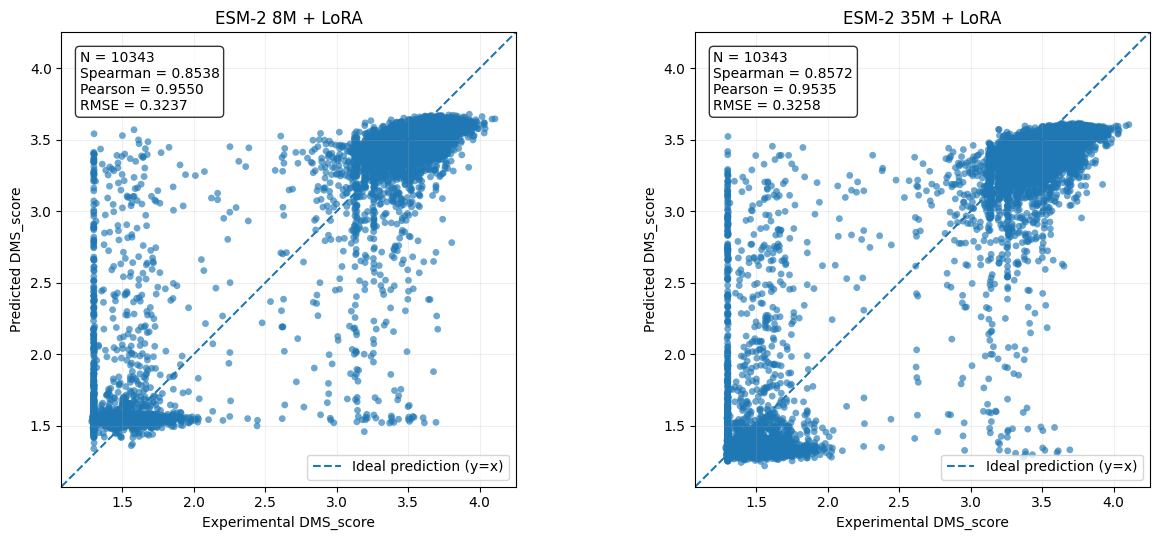

散点图已保存：/content/ESM2_8M_vs_35M_scatter.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import mean_squared_error

# 测试集真实值与预测值
y_true = np.asarray(test_metrics["y_true"])
y_pred_8m = np.asarray(test_metrics["y_pred"])

y_true_35m = np.asarray(test_metrics35["y_true"])
y_pred_35m = np.asarray(test_metrics35["y_pred"])

# 检查两个模型使用相同测试集且顺序一致
assert len(y_true) == len(y_true_35m)
assert np.allclose(y_true, y_true_35m, equal_nan=True), \
    "两个模型的测试集真实值或排列不一致，请检查数据划分。"

# 统一坐标轴范围，便于直接比较
all_values = np.concatenate([
    y_true, y_pred_8m, y_pred_35m
])
all_values = all_values[np.isfinite(all_values)]

vmin, vmax = all_values.min(), all_values.max()
margin = max((vmax - vmin) * 0.05, 0.01)
limits = (vmin - margin, vmax + margin)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

models = [
    ("ESM-2 8M + LoRA", y_true, y_pred_8m),
    ("ESM-2 35M + LoRA", y_true_35m, y_pred_35m)
]

for ax, (name, yt, yp) in zip(axes, models):
    valid = np.isfinite(yt) & np.isfinite(yp)
    yt, yp = yt[valid], yp[valid]

    rho = spearmanr(yt, yp).statistic
    r = pearsonr(yt, yp).statistic
    rmse = np.sqrt(mean_squared_error(yt, yp))

    # 真实值 vs 预测值
    ax.scatter(
        yt, yp,
        alpha=0.65,
        s=24,
        edgecolors="none"
    )

    # 理想预测线 y=x
    ax.plot(
        limits, limits,
        linestyle="--",
        linewidth=1.5,
        label="Ideal prediction (y=x)"
    )

    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("Experimental DMS_score")
    ax.set_ylabel("Predicted DMS_score")
    ax.set_title(name)

    ax.text(
        0.04, 0.96,
        f"N = {len(yt)}\n"
        f"Spearman = {rho:.4f}\n"
        f"Pearson = {r:.4f}\n"
        f"RMSE = {rmse:.4f}",
        transform=ax.transAxes,
        va="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=0.8)
    )

    ax.legend(loc="lower right")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.savefig(
    "/content/ESM2_8M_vs_35M_scatter.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("散点图已保存：/content/ESM2_8M_vs_35M_scatter.png")

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import mean_squared_error

y_true = np.asarray(test_metrics["y_true"])
pred_8m = np.asarray(test_metrics["y_pred"])
pred_35m = np.asarray(test_metrics35["y_pred"])

print("===== 8M vs 35M 诊断 =====")

print(
    "预测值 Spearman 相关性:",
    spearmanr(pred_8m, pred_35m).statistic
)

print(
    "预测值 Pearson 相关性:",
    pearsonr(pred_8m, pred_35m).statistic
)

print(
    "8M 预测标准差:",
    np.std(pred_8m)
)

print(
    "35M 预测标准差:",
    np.std(pred_35m)
)

print(
    "8M RMSE:",
    np.sqrt(mean_squared_error(y_true, pred_8m))
)

print(
    "35M RMSE:",
    np.sqrt(mean_squared_error(y_true, pred_35m))
)

print(
    "8M Spearman:",
    spearmanr(y_true, pred_8m).statistic
)

print(
    "35M Spearman:",
    spearmanr(y_true, pred_35m).statistic
)

===== 8M vs 35M 诊断 =====
预测值 Spearman 相关性: 0.9136699542372266
预测值 Pearson 相关性: 0.9706311
8M 预测标准差: 0.94234806
35M 预测标准差: 1.0027448
8M RMSE: 0.3237061757542704
35M RMSE: 0.3257991580020534
8M Spearman: 0.853822396888494
35M Spearman: 0.8571542566729563


In [ ]:

# ============================================================
# ESM-2 35M LoRA 消融实验
# 实验 A：Q/V, rank=4, lr=1e-3
# 实验 B：Q/K/V/O, rank=8, lr=1e-3
# 实验 C：Q/V, rank=8, lr=3e-4
# ============================================================

import os
import gc
import copy
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import esm

from tqdm.auto import tqdm
from scipy.stats import spearmanr, pearsonr
from sklearn.metrics import mean_squared_error

DEVICE_AB = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

SEED_AB = 42
EPOCHS_AB = 5
PATIENCE_AB = 2

OUTPUT_AB = "/content/ESM2_35M_ablation"
os.makedirs(OUTPUT_AB, exist_ok=True)

# 确认前面 Notebook 已定义这些变量
assert all(
    name in globals()
    for name in [
        "train_loader", "val_loader", "test_loader",
        "y_mean", "y_std"
    ]
), "请先运行数据处理及 DataLoader 定义部分。"

assert float(y_std) > 0, "y_std 必须大于 0。"

# 三组消融配置
CONFIGS_AB = [
    {
        "name": "A_QV_r4",
        "targets": ["q_proj", "v_proj"],
        "rank": 4,
        "alpha": 8,
        "dropout": 0.05,
        "lr": 1e-3,
    },
    {
        "name": "B_QKVO_r8",
        "targets": [
            "q_proj", "k_proj",
            "v_proj", "out_proj"
        ],
        "rank": 8,
        "alpha": 16,
        "dropout": 0.05,
        "lr": 1e-3,
    },
    {
        "name": "C_QV_r8_lowLR",
        "targets": ["q_proj", "v_proj"],
        "rank": 8,
        "alpha": 16,
        "dropout": 0.05,
        "lr": 3e-4,
    },
]


# ------------------------------------------------------------
# 1. 手写 LoRA
# ------------------------------------------------------------
class LoRALinearAB(nn.Module):
    def __init__(self, base, rank, alpha, dropout):
        super().__init__()

        self.base = base
        self.scale = alpha / rank

        for p in self.base.parameters():
            p.requires_grad = False

        self.lora_A = nn.Parameter(
            torch.empty(rank, base.in_features)
        )
        self.lora_B = nn.Parameter(
            torch.zeros(base.out_features, rank)
        )

        nn.init.kaiming_uniform_(
            self.lora_A, a=5 ** 0.5
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        original = self.base(x)

        adapted = F.linear(
            F.linear(self.dropout(x), self.lora_A),
            self.lora_B
        )

        return original + self.scale * adapted


# ------------------------------------------------------------
# 2. 加载模型，并按配置注入 LoRA
# ------------------------------------------------------------
class ESMRegressorAB(nn.Module):
    def __init__(self, backbone, alphabet):
        super().__init__()

        self.esm = backbone
        self.alphabet = alphabet

        self.regressor = nn.Sequential(
            nn.Linear(480, 128),
            nn.GELU(),
            nn.Dropout(0.2),
            nn.Linear(128, 1)
        )

    def forward(self, tokens):
        output = self.esm(
            tokens, repr_layers=[12]
        )

        h = output["representations"][12]

        mask = (
            tokens.ne(self.alphabet.padding_idx)
            & tokens.ne(self.alphabet.cls_idx)
            & tokens.ne(self.alphabet.eos_idx)
        ).unsqueeze(-1).to(h.dtype)

        pooled = (h * mask).sum(dim=1)
        pooled = pooled / mask.sum(dim=1).clamp(min=1)

        return self.regressor(pooled).squeeze(-1)


def build_model_ab(cfg):
    backbone, alphabet = esm.pretrained.esm2_t12_35M_UR50D()

    for p in backbone.parameters():
        p.requires_grad = False

    for layer in backbone.layers:
        attention = layer.self_attn

        for target in cfg["targets"]:
            old_layer = getattr(attention, target)

            setattr(
                attention,
                target,
                LoRALinearAB(
                    old_layer,
                    rank=cfg["rank"],
                    alpha=cfg["alpha"],
                    dropout=cfg["dropout"]
                )
            )

    model = ESMRegressorAB(backbone, alphabet)
    return model.to(DEVICE_AB), alphabet


# ------------------------------------------------------------
# 3. 统一评估函数
# DataLoader 中 labels 应为标准化后的标签
# ------------------------------------------------------------
def evaluate_ab(model, loader, alphabet):
    model.eval()

    true_all, pred_all = [], []

    with torch.no_grad():
        for tokens, labels in loader:
            tokens = tokens.to(DEVICE_AB)

            pred = model(tokens).cpu().numpy()
            true = labels.cpu().numpy()

            true_all.extend(true.reshape(-1))
            pred_all.extend(pred.reshape(-1))

    # 恢复原始标签尺度
    y_true = np.asarray(true_all) * float(y_std) + float(y_mean)
    y_pred = np.asarray(pred_all) * float(y_std) + float(y_mean)

    valid = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true, y_pred = y_true[valid], y_pred[valid]

    rho = spearmanr(y_true, y_pred).statistic
    pearson = pearsonr(y_true, y_pred).statistic

    return {
        "rmse": float(np.sqrt(
            mean_squared_error(y_true, y_pred)
        )),
        "spearman": float(rho),
        "pearson": float(pearson),
        "y_true": y_true,
        "y_pred": y_pred
    }


# ------------------------------------------------------------
# 4. 单组实验
# 使用验证集 Spearman 选择最佳 checkpoint
# ------------------------------------------------------------
def run_ablation_ab(cfg):
    random.seed(SEED_AB)
    np.random.seed(SEED_AB)
    torch.manual_seed(SEED_AB)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED_AB)

    model, alphabet = build_model_ab(cfg)

    trainable = [
        p for p in model.parameters()
        if p.requires_grad
    ]

    print(
        f"\n{cfg['name']} | "
        f"可训练参数={sum(p.numel() for p in trainable):,}"
    )

    optimizer = torch.optim.AdamW(
        trainable,
        lr=cfg["lr"],
        weight_decay=0.01
    )

    best_score = -float("inf")
    best_state = None
    best_epoch = 0
    bad_epochs = 0
    history = []

    for epoch in range(EPOCHS_AB):
        model.train()
        train_losses = []

        for tokens, labels in tqdm(
            train_loader,
            desc=f"{cfg['name']} epoch {epoch+1}"
        ):
            tokens = tokens.to(DEVICE_AB)
            labels = labels.to(DEVICE_AB).float().reshape(-1)

            optimizer.zero_grad(set_to_none=True)

            pred = model(tokens)
            loss = F.mse_loss(pred, labels)

            loss.backward()
            torch.nn.utils.clip_grad_norm_(
                trainable, max_norm=1.0
            )
            optimizer.step()

            train_losses.append(loss.item())

        val = evaluate_ab(model, val_loader, alphabet)

        history.append({
            "epoch": epoch + 1,
            "train_mse": float(np.mean(train_losses)),
            "val_rmse": val["rmse"],
            "val_spearman": val["spearman"],
            "val_pearson": val["pearson"]
        })

        print(
            f"Epoch {epoch+1} | "
            f"Train MSE={np.mean(train_losses):.4f} | "
            f"Val Spearman={val['spearman']:.4f} | "
            f"Val RMSE={val['rmse']:.4f}"
        )

        # 按验证集 Spearman 保存最佳状态
        score = val["spearman"]

        if np.isfinite(score) and score > best_score:
            best_score = score
            best_epoch = epoch + 1

            best_state = {
                name: p.detach().cpu().clone()
                for name, p in model.named_parameters()
                if p.requires_grad
            }
            bad_epochs = 0
        else:
            bad_epochs += 1

        if bad_epochs >= PATIENCE_AB:
            print("Early stopping")
            break

    if best_state is None:
        raise RuntimeError(
            f"{cfg['name']} 未得到有效验证集结果。"
        )

    # 恢复最佳参数
    with torch.no_grad():
        for name, p in model.named_parameters():
            if p.requires_grad:
                p.copy_(best_state[name].to(p.device))

    # 保存该组最佳 LoRA 参数及训练记录
    torch.save(
        {
            "config": cfg,
            "trainable_state": best_state,
            "best_epoch": best_epoch,
            "best_val_spearman": best_score,
            "y_mean": float(y_mean),
            "y_std": float(y_std)
        },
        os.path.join(
            OUTPUT_AB, f"{cfg['name']}.pt"
        )
    )

    pd.DataFrame(history).to_csv(
        os.path.join(
            OUTPUT_AB, f"{cfg['name']}_history.csv"
        ),
        index=False
    )

    # 最终测试评估
    test_result = evaluate_ab(model, test_loader, alphabet)

    result = {
        "experiment": cfg["name"],
        "targets": ",".join(cfg["targets"]),
        "rank": cfg["rank"],
        "alpha": cfg["alpha"],
        "lr": cfg["lr"],
        "trainable_params": sum(
            p.numel() for p in trainable
        ),
        "best_epoch": best_epoch,
        "best_val_spearman": best_score,
        "test_spearman": test_result["spearman"],
        "test_pearson": test_result["pearson"],
        "test_rmse": test_result["rmse"]
    }

    del model, optimizer, trainable
    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result


# ------------------------------------------------------------
# 5. 运行全部实验
# ------------------------------------------------------------
results_ab = []

for cfg in CONFIGS_AB:
    results_ab.append(run_ablation_ab(cfg))

ablation_df = pd.DataFrame(results_ab)

ablation_df.to_csv(
    os.path.join(OUTPUT_AB, "ablation_results.csv"),
    index=False
)

display(
    ablation_df.sort_values(
        "best_val_spearman",
        ascending=False
    ).round(5)
)

print("结果保存目录:", OUTPUT_AB)



A_QV_r4 | 可训练参数=153,857


A_QV_r4 epoch 1:   0%|          | 0/2198 [00:00<?, ?it/s]

Epoch 1 | Train MSE=0.4628 | Val Spearman=0.8065 | Val RMSE=0.6025


A_QV_r4 epoch 2:   0%|          | 0/2198 [00:00<?, ?it/s]

Epoch 2 | Train MSE=0.2572 | Val Spearman=0.8324 | Val RMSE=0.4775


...

Epoch 4 | Train MSE=0.1719 | Val Spearman=0.8494 | Val RMSE=0.3391


C_QV_r8_lowLR epoch 5:   0%|          | 0/2198 [00:00<?, ?it/s]

Epoch 5 | Train MSE=0.1407 | Val Spearman=0.8407 | Val RMSE=0.9316


,experiment,targets,rank,alpha,lr,trainable_params,best_epoch,best_val_spearman,test_spearman,test_pearson,test_rmse
0,A_QV_r4,"q_proj,v_proj",4,8,0.0010,153857,5,0.85364,0.85715,0.95355,0.32580
2,C_QV_r8_lowLR,"q_proj,v_proj",8,16,0.0003,246017,4,0.84939,0.85344,0.94754,0.33861
1,B_QKVO_r8,"q_proj,k_proj,v_proj,out_proj",8,16,0.0010,430337,2,0.30787,0.32290,0.35588,1.05903


结果保存目录: /content/ESM2_35M_ablation
